## Weather and Travel-Mode Mobility Patterns (Flag 16)

### Dataset Overview

A constructed WorldTrace case with 320 trajectories. Geometry source: Observed map-matched NYC WorldTrace road paths or continuous road-aligned return traversals. Environmental, temporal, mode, vehicle, and event attributes are arranged to make all stated comparisons measurable without changing the route coordinates used by the figures.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Identify the mobility patterns across weather and travel-mode conditions based on the given trajectories.

Role: Urban mobility analyst


Category: Weather, mode choice, distance, speed, and GPS alignment


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does the share of car trips differ under rainy, cold, and mild conditions?

#### Analysis action

Derive rainy and cold directly from native fields and compare the car share against mild conditions.

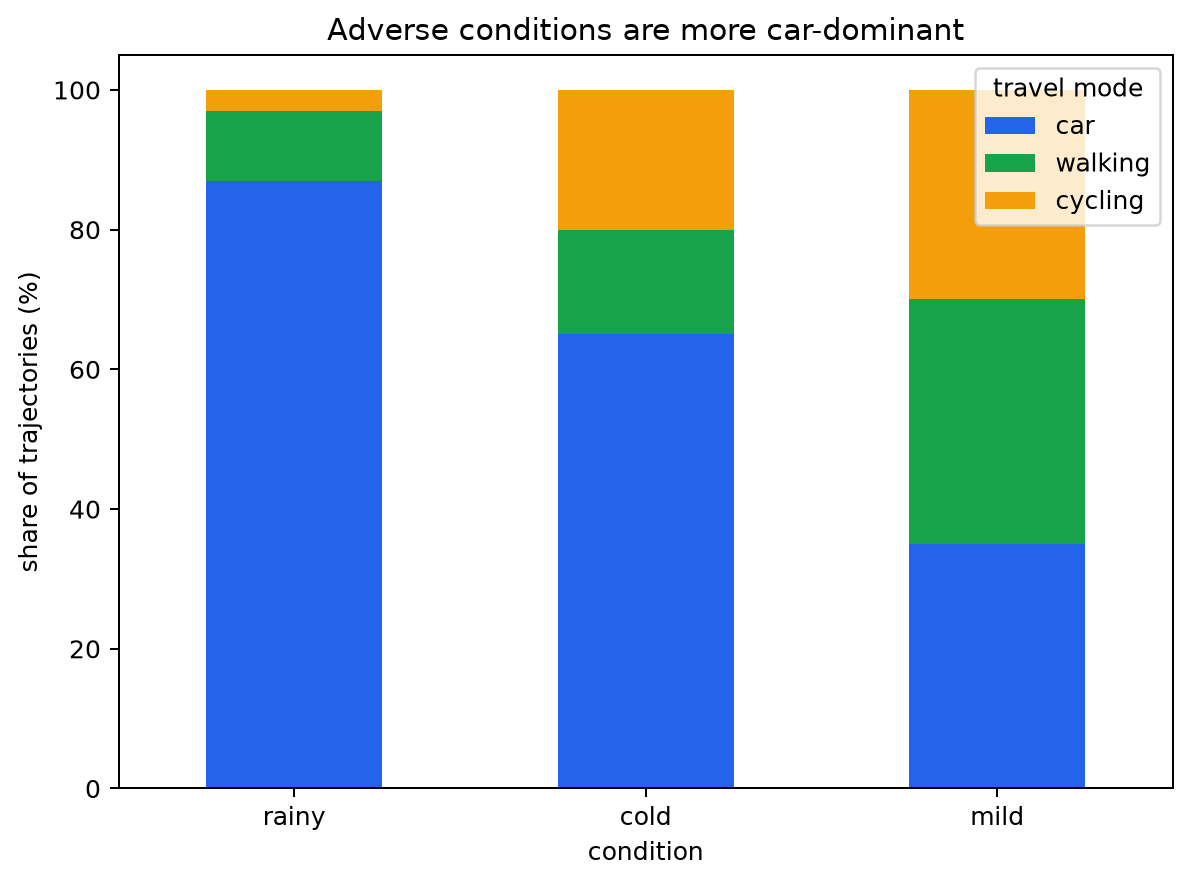

In [ ]:
x = df.copy()
x["schema_condition"] = np.select(
    [x.weather.eq("rainy"), x.temperature_c.eq(5) & ~x.weather.eq("rainy")],
    ["rainy", "cold"],
    default="mild",
)
order = ["rainy", "cold", "mild"]
tab = (
    pd.crosstab(x.schema_condition, x.travel_mode, normalize="index").reindex(order)[
        ["car", "walking", "cycling"]
    ]
    * 100
)
print("Mode share (%)")
print(tab.round(1))
fig, ax = plt.subplots(figsize=(6.5, 4.8), constrained_layout=True)
tab.plot.bar(stacked=True, ax=ax, color=["#2563eb", "#16a34a", "#f59e0b"])
ax.set(
    title="Adverse conditions are more car-dominant",
    xlabel="condition",
    ylabel="share of trajectories (%)",
)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="travel mode")
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex16_insight_1",
  "insight": "Under rainy or cold conditions, car trips account for a larger share of the observed trajectories.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_1.png"
    ],
    "title": "Weather and Travel-Mode Mobility Patterns: Insight 1",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "How does the share of car trips differ under rainy, cold, and mild conditions?",
  "actionable_insight": "Derive rainy and cold directly from native fields and compare the car share against mild conditions.",
  "code": "x=df.copy()\nx['schema_condition']=np.select([x.weather.eq('rainy'),x.temperature_c.eq(5)&~x.weather.eq('rainy')],['rainy','cold'],default='mild')\norder=['rainy','cold','mild'];tab=pd.crosstab(x.schema_condition,x.travel_mode,normalize='index').reindex(order)[['car','walking','cycling']]*100\nprint('Mode share (%)');print(tab.round(1))\nfig,ax=plt.subplots(figsize=(6.5,4.8),constrained_layout=True)\ntab.plot.bar(stacked=True,ax=ax,color=['#2563eb','#16a34a','#f59e0b'])\nax.set(title='Adverse conditions are more car-dominant',xlabel='condition',ylabel='share of trajectories (%)');ax.tick_params(axis='x',rotation=0);ax.legend(title='travel mode')\nplt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "weather",
    "temperature",
    "trajectory_id",
    "matched_road_position"
  ]
}

### **Question 2**: What is the conditional walking pattern P(speed | weather, temperature), and how do distance and spatial extent differ between adverse and mild conditions?

#### Analysis action

Use every weather-temperature cell specified in the YAML, then compare walking distance and per-trajectory endpoint displacement between adverse and mild conditions.

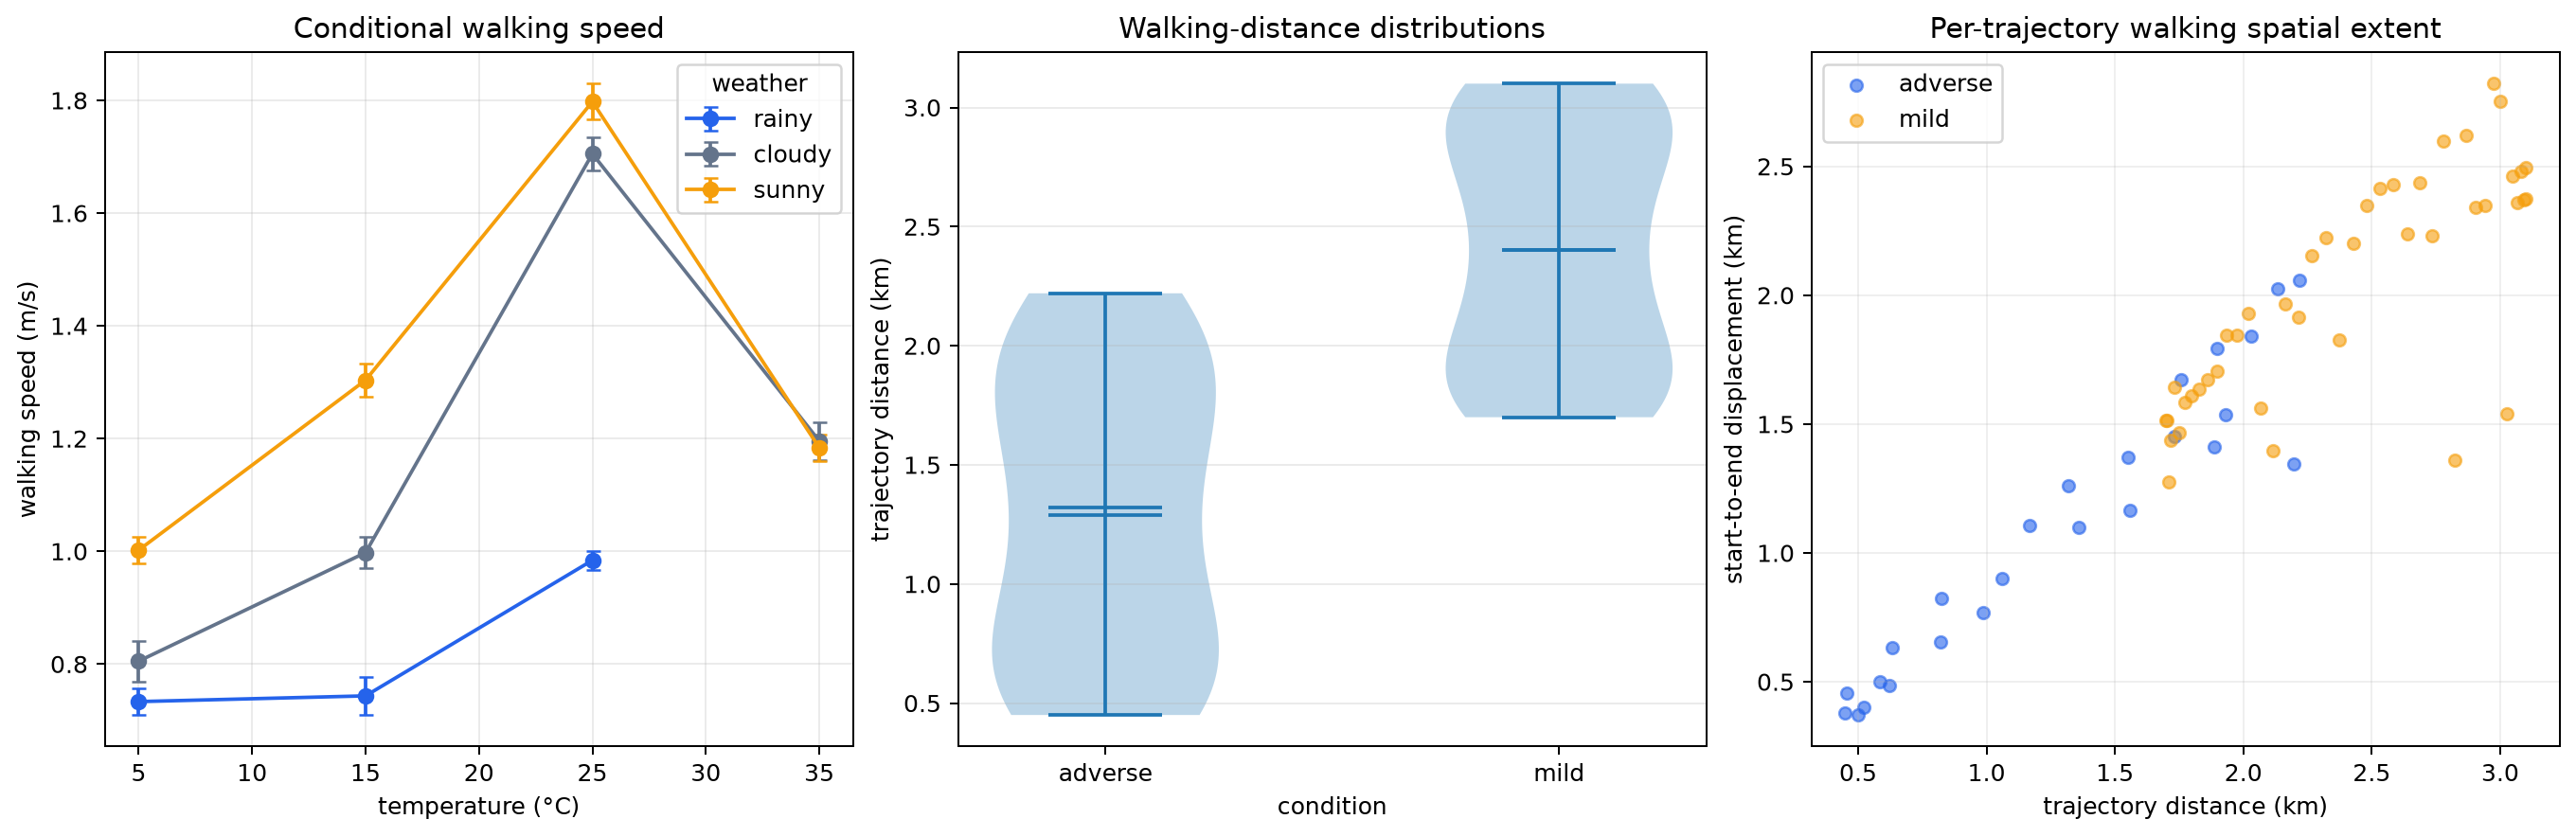

In [ ]:
w = df[df.travel_mode.eq("walking")].copy()
w["speed_mps"] = w.mean_speed_kmh / 3.6
conditional = w.groupby(["weather", "temperature_c"]).agg(
    trips=("trajectory_id", "size"),
    speed_mps=("speed_mps", "mean"),
    speed_sd=("speed_mps", "std"),
    distance_km=("trajectory_distance_km", "mean"),
)
print("P(speed | weather, temperature) summary")
print(conditional.round(3))
w["weather_group"] = np.where(
    w.condition_group.str.startswith("adverse"), "adverse", "mild"
)
print("Adverse/mild trajectory-extent summary")
print(
    w.groupby("weather_group")
    .agg(
        trips=("trajectory_id", "size"),
        distance_km=("trajectory_distance_km", "mean"),
        endpoint_displacement_km=("straight_line_distance_km", "mean"),
    )
    .round(3)
)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)
colors = {"rainy": "#2563eb", "cloudy": "#64748b", "sunny": "#f59e0b"}
for weather, color in colors.items():
    q = conditional.xs(weather, level="weather")
    ax[0].errorbar(
        q.index,
        q.speed_mps,
        yerr=q.speed_sd.fillna(0),
        marker="o",
        capsize=3,
        label=weather,
        color=color,
    )
ax[0].set(
    title="Conditional walking speed",
    xlabel="temperature (°C)",
    ylabel="walking speed (m/s)",
)
ax[0].legend(title="weather")
ax[0].grid(alpha=0.25)
groups = [w[w.weather_group.eq(k)].trajectory_distance_km for k in ["adverse", "mild"]]
parts = ax[1].violinplot(groups, showmeans=True, showmedians=True)
ax[1].set_xticks([1, 2], ["adverse", "mild"])
ax[1].set(
    title="Walking-distance distributions",
    xlabel="condition",
    ylabel="trajectory distance (km)",
)
ax[1].grid(axis="y", alpha=0.25)
for group, color in [("adverse", "#2563eb"), ("mild", "#f59e0b")]:
    q = w[w.weather_group.eq(group)]
    ax[2].scatter(
        q.trajectory_distance_km,
        q.straight_line_distance_km,
        s=26,
        alpha=0.6,
        label=group,
        color=color,
    )
ax[2].set(
    title="Per-trajectory walking spatial extent",
    xlabel="trajectory distance (km)",
    ylabel="start-to-end displacement (km)",
)
ax[2].legend()
ax[2].grid(alpha=0.2)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex16_insight_2",
  "insight": "Walking trajectories recorded under mild weather and temperature conditions cover longer distances and show greater spatial extent, whereas walking during adverse weather remains more spatially compact and slower.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_2.png"
    ],
    "title": "Weather and Travel-Mode Mobility Patterns: Insight 2",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "What is the conditional walking pattern P(speed | weather, temperature), and how do distance and spatial extent differ between adverse and mild conditions?",
  "actionable_insight": "Use every weather-temperature cell specified in the YAML, then compare walking distance and per-trajectory endpoint displacement between adverse and mild conditions.",
  "code": "w=df[df.travel_mode.eq('walking')].copy();w['speed_mps']=w.mean_speed_kmh/3.6\nconditional=w.groupby(['weather','temperature_c']).agg(trips=('trajectory_id','size'),speed_mps=('speed_mps','mean'),speed_sd=('speed_mps','std'),distance_km=('trajectory_distance_km','mean'))\nprint('P(speed | weather, temperature) summary');print(conditional.round(3))\nw['weather_group']=np.where(w.condition_group.str.startswith('adverse'),'adverse','mild')\nprint('Adverse/mild trajectory-extent summary');print(w.groupby('weather_group').agg(trips=('trajectory_id','size'),distance_km=('trajectory_distance_km','mean'),endpoint_displacement_km=('straight_line_distance_km','mean')).round(3))\nfig,ax=plt.subplots(1,3,figsize=(15,4.8),constrained_layout=True)\ncolors={'rainy':'#2563eb','cloudy':'#64748b','sunny':'#f59e0b'}\nfor weather,color in colors.items():\n    q=conditional.xs(weather,level='weather');ax[0].errorbar(q.index,q.speed_mps,yerr=q.speed_sd.fillna(0),marker='o',capsize=3,label=weather,color=color)\nax[0].set(title='Conditional walking speed',xlabel='temperature (°C)',ylabel='walking speed (m/s)');ax[0].legend(title='weather');ax[0].grid(alpha=.25)\ngroups=[w[w.weather_group.eq(k)].trajectory_distance_km for k in ['adverse','mild']]\nparts=ax[1].violinplot(groups,showmeans=True,showmedians=True);ax[1].set_xticks([1,2],['adverse','mild']);ax[1].set(title='Walking-distance distributions',xlabel='condition',ylabel='trajectory distance (km)');ax[1].grid(axis='y',alpha=.25)\nfor group,color in [('adverse','#2563eb'),('mild','#f59e0b')]:\n    q=w[w.weather_group.eq(group)];ax[2].scatter(q.trajectory_distance_km,q.straight_line_distance_km,s=26,alpha=.6,label=group,color=color)\nax[2].set(title='Per-trajectory walking spatial extent',xlabel='trajectory distance (km)',ylabel='start-to-end displacement (km)');ax[2].legend();ax[2].grid(alpha=.2)\nplt.show()",
  "insight_type": "factor_relationship",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "matched_road_position",
    "transport_mode",
    "weather",
    "temperature",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 3**: Among car trips, how do speed level, speed stability, and GPS-to-road alignment vary with adverse weather, especially in highly turning sections?

#### Analysis action

Compare adverse and mild/dry car speed statistics, then show the interaction between weather condition and high-turn road segments for GPS-road offset.

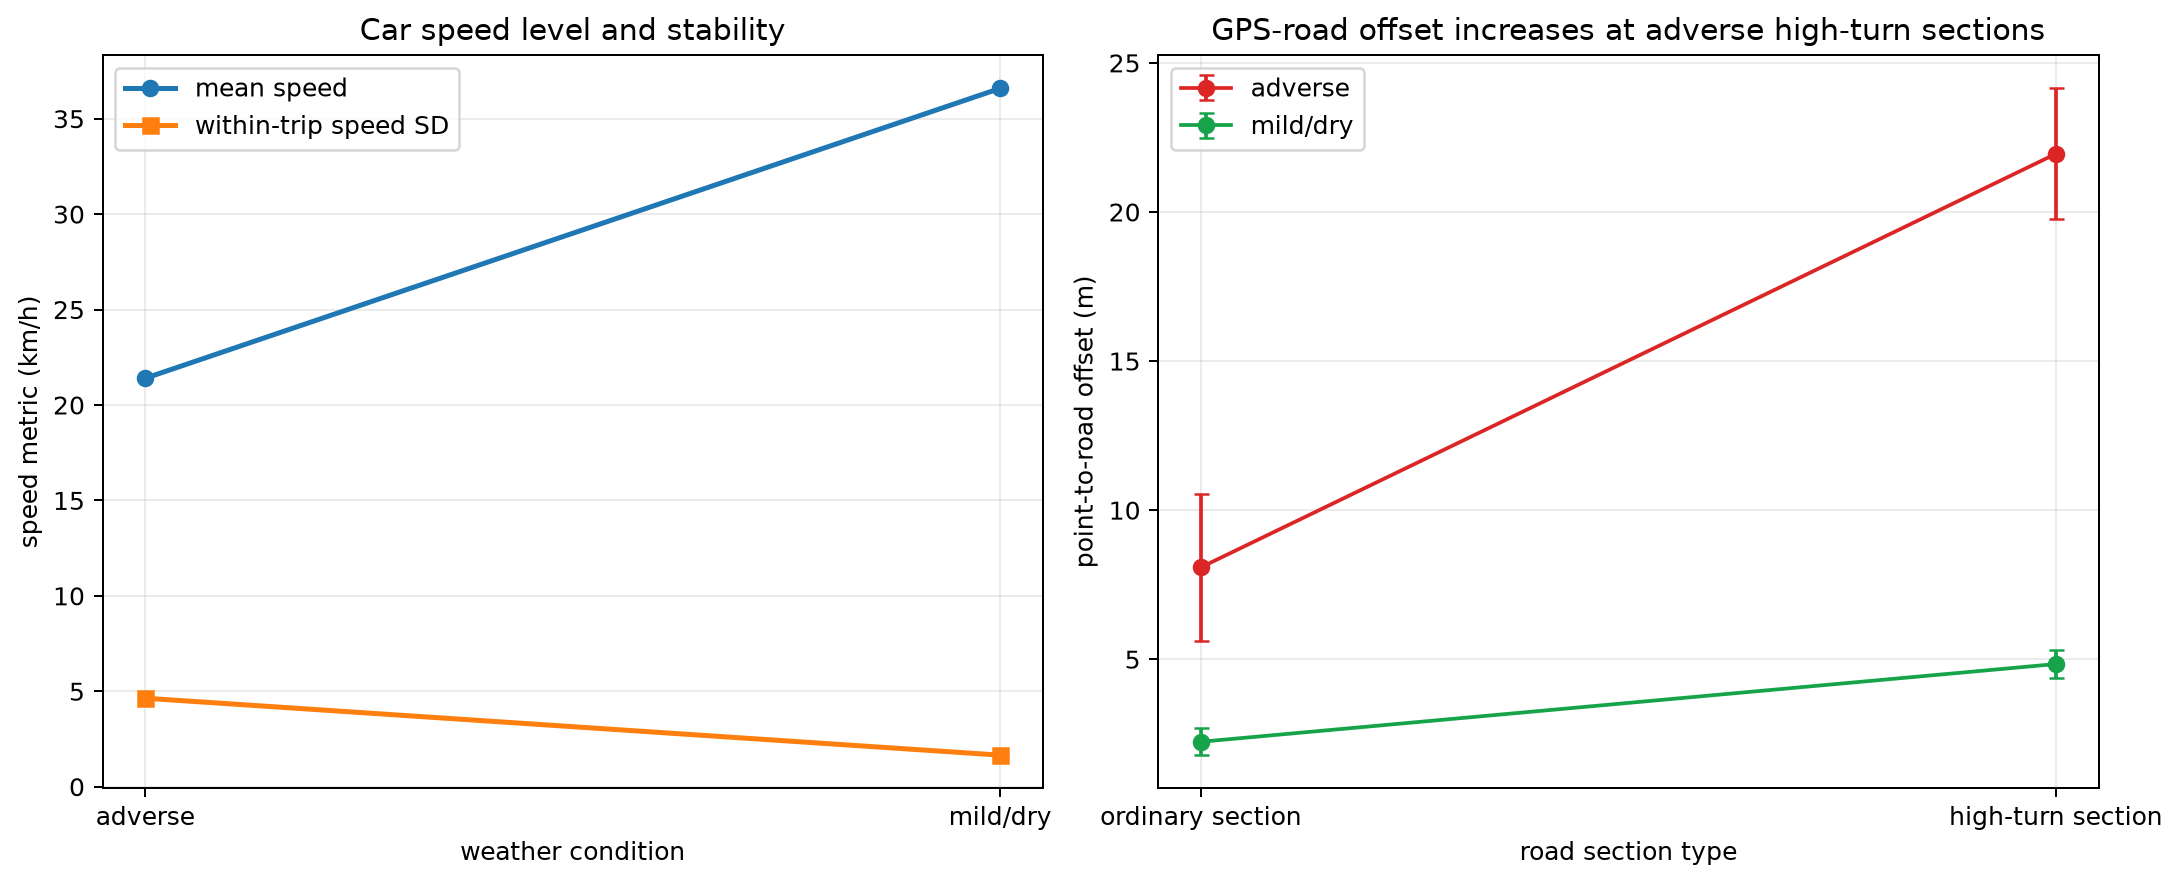

In [ ]:
c = df[df.travel_mode.eq("car")].copy()
c["weather_group"] = np.where(
    c.condition_group.str.startswith("adverse"), "adverse", "mild/dry"
)
g = (
    c.groupby("weather_group")
    .agg(
        mean_speed=("mean_speed_kmh", "mean"),
        within_speed_sd=("within_trip_speed_sd_kmh", "mean"),
        mean_offset=("mean_gps_road_offset_m", "mean"),
    )
    .reindex(["adverse", "mild/dry"])
)
q = user_df[user_df.travel_mode.eq("car")].copy()
q["weather_group"] = np.where(
    q.condition_group.str.startswith("adverse"), "adverse", "mild/dry"
)
h = q.groupby(["weather_group", "is_high_turn_segment"]).distance_to_matched_road_m.agg(
    ["mean", "std", "count"]
)
print("Car trajectory summary")
print(g.round(2))
print("GPS-road offset by weather and turning section")
print(h.round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
pos = np.arange(len(g))
ax[0].plot(pos, g.mean_speed, marker="o", linewidth=2, label="mean speed")
ax[0].plot(
    pos, g.within_speed_sd, marker="s", linewidth=2, label="within-trip speed SD"
)
ax[0].set_xticks(pos, g.index)
ax[0].set(
    title="Car speed level and stability",
    xlabel="weather condition",
    ylabel="speed metric (km/h)",
)
ax[0].legend()
ax[0].grid(alpha=0.25)
for group, color in [("adverse", "#dc2626"), ("mild/dry", "#16a34a")]:
    z = h.loc[group]
    ax[1].errorbar(
        [0, 1],
        z["mean"],
        yerr=z["std"],
        marker="o",
        capsize=3,
        label=group,
        color=color,
    )
ax[1].set_xticks([0, 1], ["ordinary section", "high-turn section"])
ax[1].set(
    title="GPS-road offset increases at adverse high-turn sections",
    xlabel="road section type",
    ylabel="point-to-road offset (m)",
)
ax[1].legend()
ax[1].grid(alpha=0.25)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex16_insight_3",
  "insight": "Among car trips, adverse-weather trajectories show lower speeds and greater point-to-road offsets for GPS data in highly turning sections, while dry-weather trajectories maintain more stable speeds and closer road alignment",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_3.png"
    ],
    "title": "Weather and Travel-Mode Mobility Patterns: Insight 3",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "Among car trips, how do speed level, speed stability, and GPS-to-road alignment vary with adverse weather, especially in highly turning sections?",
  "actionable_insight": "Compare adverse and mild/dry car speed statistics, then show the interaction between weather condition and high-turn road segments for GPS-road offset.",
  "code": "c=df[df.travel_mode.eq('car')].copy();c['weather_group']=np.where(c.condition_group.str.startswith('adverse'),'adverse','mild/dry')\ng=c.groupby('weather_group').agg(mean_speed=('mean_speed_kmh','mean'),within_speed_sd=('within_trip_speed_sd_kmh','mean'),mean_offset=('mean_gps_road_offset_m','mean')).reindex(['adverse','mild/dry'])\nq=user_df[user_df.travel_mode.eq('car')].copy();q['weather_group']=np.where(q.condition_group.str.startswith('adverse'),'adverse','mild/dry')\nh=q.groupby(['weather_group','is_high_turn_segment']).distance_to_matched_road_m.agg(['mean','std','count'])\nprint('Car trajectory summary');print(g.round(2));print('GPS-road offset by weather and turning section');print(h.round(2))\nfig,ax=plt.subplots(1,2,figsize=(12,4.8),constrained_layout=True)\npos=np.arange(len(g));ax[0].plot(pos,g.mean_speed,marker='o',linewidth=2,label='mean speed');ax[0].plot(pos,g.within_speed_sd,marker='s',linewidth=2,label='within-trip speed SD')\nax[0].set_xticks(pos,g.index);ax[0].set(title='Car speed level and stability',xlabel='weather condition',ylabel='speed metric (km/h)');ax[0].legend();ax[0].grid(alpha=.25)\nfor group,color in [('adverse','#dc2626'),('mild/dry','#16a34a')]:\n    z=h.loc[group];ax[1].errorbar([0,1],z['mean'],yerr=z['std'],marker='o',capsize=3,label=group,color=color)\nax[1].set_xticks([0,1],['ordinary section','high-turn section']);ax[1].set(title='GPS-road offset increases at adverse high-turn sections',xlabel='road section type',ylabel='point-to-road offset (m)');ax[1].legend();ax[1].grid(alpha=.25)\nplt.show()",
  "insight_type": "factor_relationship",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "matched_road_position",
    "transport_mode",
    "weather",
    "trajectory_timestamp",
    "trajectory_id",
    "temperature"
  ]
}

### Summary of Findings (Flag 16)

Under rainy or cold conditions, car trips account for a larger share of the observed trajectories. Walking trajectories recorded under mild weather and temperature conditions cover longer distances and show greater spatial extent, whereas walking during adverse weather remains more spatially compact and slower. Among car trips, adverse-weather trajectories show lower speeds and greater point-to-road offsets for GPS data in highly turning sections, while dry-weather trajectories maintain more stable speeds and closer road alignment